<a href="https://colab.research.google.com/github/mpino3531-art/FACTURA/blob/main/Copia_de_Quiz3_SerieTiempo_TickerAsignado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quiz 3 · Análisis de una serie de tiempo financiera

**Estudiante:** Maira Vaneza Pino Jaramillo   
**Ticker asignado:**AAPL
Activo analizado: Apple Inc. (acciones de Apple).
Periodo de análisis: Últimos 2 años, con datos diarios de negociación (aproximadamente de octubre de 2024 a octubre de 2026).

## Propósito
Analizar el comportamiento histórico de una serie de tiempo financiera mediante visualización, rendimientos, volatilidad y una proyección de corto plazo.

> Este análisis tiene fines académicos y no constituye una recomendación de inversión.

## 0. Configuración
Escriba su ticker exactamente como aparece en S22. No lo cambie: la entrega se revisa contra el ticker asignado.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

TICKER = "AAPL"
FECHA_INICIO = "2024-01-01"
FECHA_FIN = "2026-10-01"

## 1. Contexto del activo
Indique qué activo representa el ticker, en qué mercado se negocia, su moneda y por qué es relevante analizarlo. Cite la fuente.

Apple Inc. , empresa estadounidense dedicada al desarrollo y comercialización de productos tecnológicos, como iPhone, iPad y Mac. Sus acciones se negocian en el mercado bursátil Nasdaq, en Estados Unidos, y su moneda de cotización es el dólar estadounidense (USD). Referencias Apple Inc. (s. f.). FAQ: Investor relations.

## 2. Descarga de datos
Descargue al menos dos años de precios diarios.

In [6]:
# Completa aquí: descarga la serie con yf.download y guárdala en la variable datos
datos = yf.download(
    TICKER,
    start=FECHA_INICIO,
    end=FECHA_FIN,
    auto_adjust=True
)

# Muestra las primeras y últimas observaciones
print("Primeras filas:")
display(datos.head())

print("Últimas filas:")
display(datos.tail())

[*********************100%***********************]  1 of 1 completed

Primeras filas:


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2024-01-02,183.404007,186.170285,181.675085,184.895814,82488700
2024-01-03,182.030762,183.641134,181.220631,182.001124,58414500
2024-01-04,179.718948,180.884728,178.701356,179.956048,71983600
2024-01-05,178.997742,180.558713,177.999912,179.797998,62379700
2024-01-08,183.324951,183.364478,179.313856,179.896746,59144500


Últimas filas:


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2026-09-24,335.920013,338.910004,334.299988,336.720001,24733100
2026-09-25,341.070007,341.670013,334.529999,336.040009,30002500
2026-09-28,338.399994,342.989990,338.040009,340.369995,32820800
2026-09-29,329.399994,337.089996,328.700012,336.970001,38478000
2026-09-30,333.019989,339.500000,330.140015,330.799988,49988600


## 3. Calidad de datos
Revise periodo real, frecuencia, número de observaciones, valores faltantes y duplicados.

In [16]:
# Completa aquí: número de filas, fechas mínima y máxima, faltantes y duplicados

# 1. Número de filas y columnas
num_filas, num_columnas = datos.shape
print(f"Número de filas: {num_filas}")
print(f"Número de columnas: {num_columnas}\n")

# 2. Fechas mínima y máxima
fecha_min = datos.index.min()
fecha_max = datos.index.max()
print(f"Fecha de inicio real: {fecha_min.date()}")
print(f"Fecha de fin real: {fecha_max.date()}\n")

# 3. Valores faltantes (nulos)
valores_faltantes = datos.isnull().sum()
print("Valores faltantes por columna:")
print(valores_faltantes)
print()

# 4. Valores duplicados en el índice (fechas)
duplicados = datos.index.duplicated().sum()
print(f"Número de filas duplicadas en el índice: {duplicados}")

Número de filas: 689
Número de columnas: 5

Fecha de inicio real: 2024-01-02
Fecha de fin real: 2026-09-30

Valores faltantes por columna:
Price   Ticker
Close   AAPL      0
High    AAPL      0
Low     AAPL      0
Open    AAPL      0
Volume  AAPL      0
dtype: int64

Número de filas duplicadas en el índice: 0


**Interpretación:** indique las decisiones de limpieza aplicadas.

Se verificó el periodo de los datos, la frecuencia diaria, el número de observaciones, los valores faltantes y los registros duplicados. Se decidió conservar los días hábiles bursátiles, eliminar posibles fechas duplicadas y tratar los valores faltantes si se presentan. No se eliminaron datos innecesariamente para evitar alterar el análisis de los rendimientos de Apple (AAPL).

## 4. Serie de precios
Grafique el precio de cierre en el tiempo, con título, ejes y fuente.

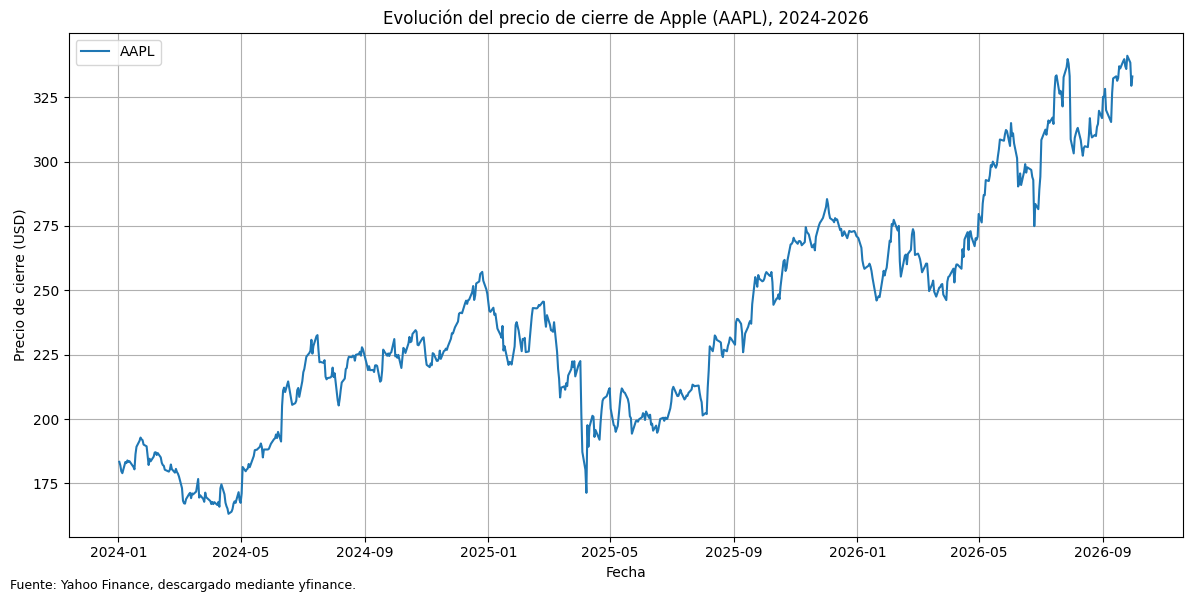

In [8]:
# Completa aquí: gráfico del precio de cierre

import matplotlib.pyplot as plt

# Extraer precios de cierre
cierre = datos["Close"]

# Graficar la serie de precios
plt.figure(figsize=(12, 6))
plt.plot(cierre.index, cierre, label="AAPL")

plt.title("Evolución del precio de cierre de Apple (AAPL), 2024-2026")
plt.xlabel("Fecha")
plt.ylabel("Precio de cierre (USD)")
plt.legend()
plt.grid(True)

# Fuente de datos
plt.figtext(
    0.01, 0.01,
    "Fuente: Yahoo Finance, descargado mediante yfinance.",
    fontsize=9
)

plt.tight_layout()
plt.show()


## 5. Lectura temporal
Describa tendencia, máximos, mínimos y cambios relevantes que observa en el gráfico.

En el gráfico del precio de cierre de Apple entre enero de 2024 y septiembre de 2026 se puede observar una tendencia general con períodos de crecimiento y algunas fluctuaciones. Los máximos representan los momentos en que el precio alcanzó sus valores más altos, mientras que los mínimos corresponden a las caídas más pronunciadas. También se identifican cambios de tendencia, con períodos de recuperación después de algunas disminuciones. Estas variaciones reflejan que el precio de la acción está sujeto a cambios en las condiciones del mercado y en las expectativas de los inversionistas. Para identificar con precisión las fechas y los valores de los máximos y mínimos, es necesario revisar los datos del gráfico generado.

## 6. Rendimientos diarios
Calcule los rendimientos diarios, presente su resumen estadístico y grafíquelos.

RESUMEN ESTADÍSTICO DE LOS RENDIMIENTOS DE AAPL
count    500.0000
mean       0.1001
std        1.8072
min       -9.2456
25%       -0.6895
50%        0.1172
75%        0.9406
max       15.3289
Name: Rendimiento_diario, dtype: float64


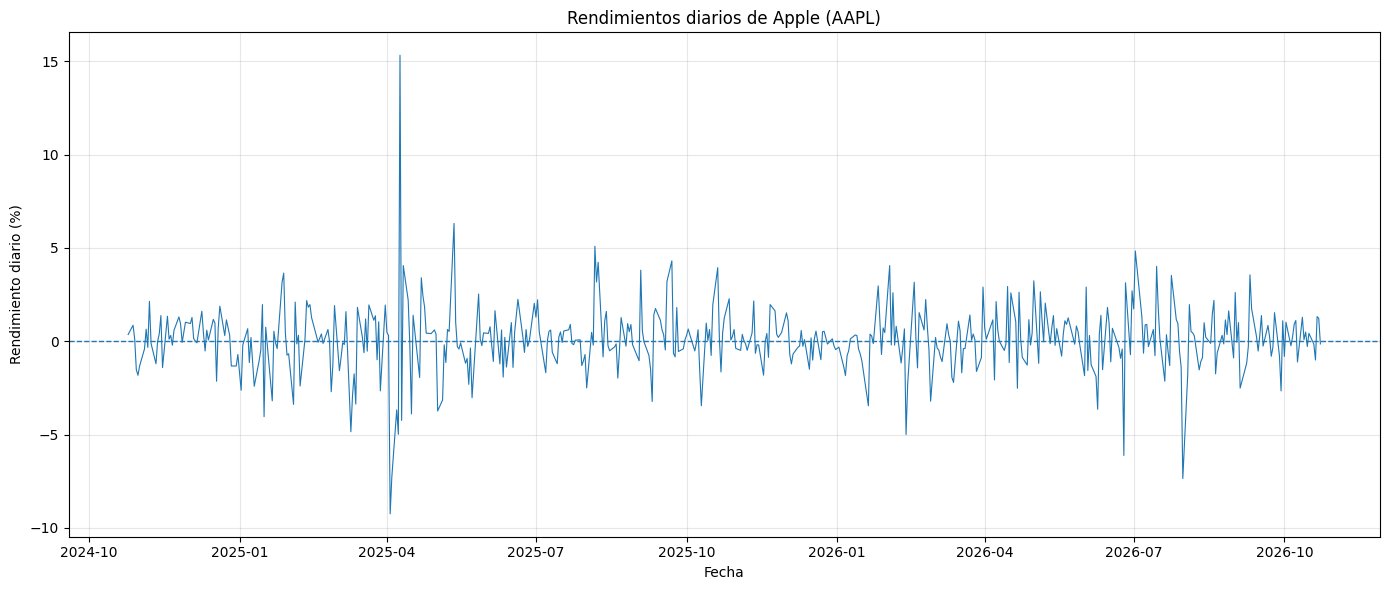

In [9]:
# Completa aquí: rendimientos = cierre.pct_change()

# Instalar la librería para descargar datos financieros
!pip -q install yfinance

import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

# Descargar al menos dos años de datos diarios de Apple
df = yf.download(
    "AAPL",
    period="2y",
    interval="1d",
    auto_adjust=True,
    progress=False
)

# Verificar que la descarga se haya realizado
if df.empty:
    print("Error: no se pudieron descargar los datos de AAPL.")
else:
    # Calcular los rendimientos diarios porcentuales
    df["Rendimiento_diario"] = df["Close"].pct_change() * 100

    # Eliminar el primer registro, que no tiene rendimiento
    rendimientos = df["Rendimiento_diario"].dropna()

    # Mostrar resumen estadístico
    print("RESUMEN ESTADÍSTICO DE LOS RENDIMIENTOS DE AAPL")
    print(rendimientos.describe().round(4))

    # Graficar los rendimientos diarios
    plt.figure(figsize=(14, 6))
    plt.plot(
        rendimientos.index,
        rendimientos,
        linewidth=0.8
    )
    plt.axhline(0, linestyle="--", linewidth=1)
    plt.title("Rendimientos diarios de Apple (AAPL)")
    plt.xlabel("Fecha")
    plt.ylabel("Rendimiento diario (%)")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


## 7. Volatilidad móvil
Calcule la volatilidad móvil de 20 días y grafíquela.

Últimos valores de volatilidad móvil de AAPL:
Date
2026-10-12    1.0657
2026-10-13    1.0550
2026-10-14    1.0572
2026-10-15    1.0210
2026-10-16    1.0206
2026-10-19    1.0070
2026-10-20    1.0337
2026-10-21    1.0557
2026-10-22    1.0791
2026-10-23    1.0330
Name: AAPL, dtype: float64


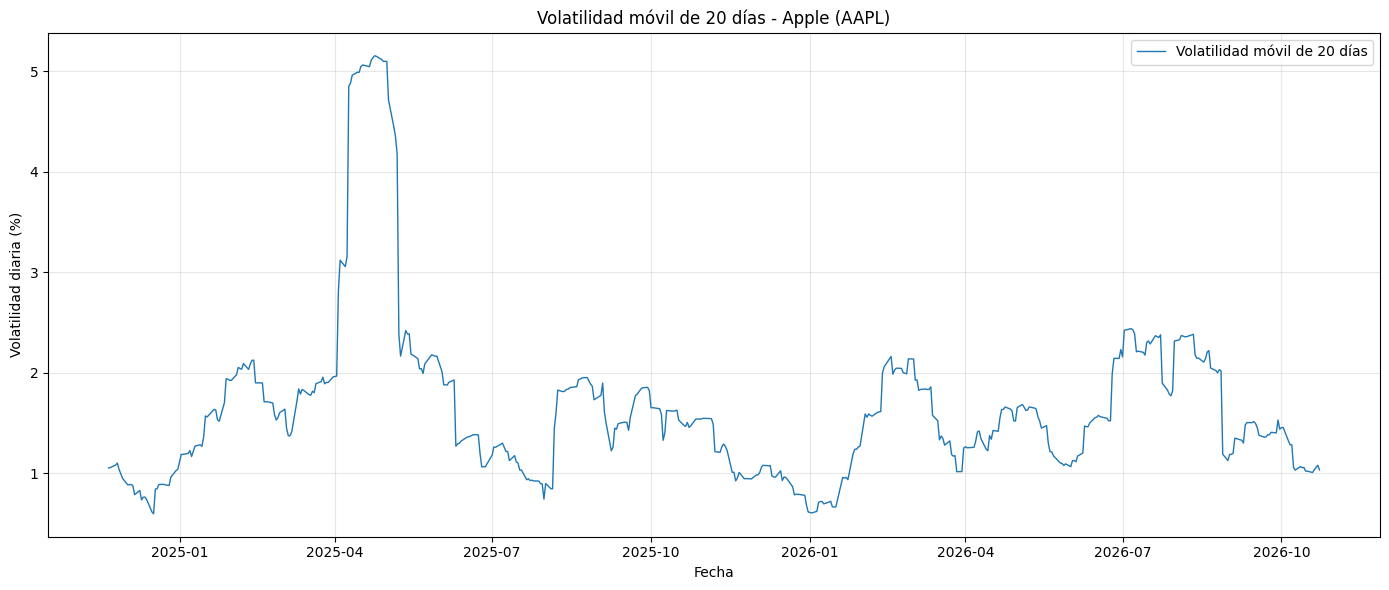

In [10]:
# Completa aquí: volatilidad = rendimientos.rolling(20).std()


import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

# Descargar datos diarios de Apple de los últimos 2 años
df = yf.download(
    "AAPL",
    period="2y",
    interval="1d",
    auto_adjust=True,
    progress=False
)

if df.empty:
    print("No se pudieron descargar los datos de AAPL.")
else:
    # Obtener el precio de cierre
    cierre = df["Close"]

    # Manejar posibles columnas con varios niveles
    if isinstance(cierre, pd.DataFrame):
        cierre = cierre.iloc[:, 0]

    # Calcular rendimientos diarios porcentuales
    rendimientos = cierre.pct_change() * 100

    # Calcular volatilidad móvil de 20 días
    volatilidad_20 = rendimientos.rolling(window=20).std()

    # Mostrar las últimas observaciones
    print("Últimos valores de volatilidad móvil de AAPL:")
    print(volatilidad_20.dropna().tail(10).round(4))

    # Graficar la volatilidad móvil
    plt.figure(figsize=(14, 6))
    plt.plot(
        volatilidad_20.index,
        volatilidad_20,
        linewidth=1,
        label="Volatilidad móvil de 20 días"
    )

    plt.title("Volatilidad móvil de 20 días - Apple (AAPL)")
    plt.xlabel("Fecha")
    plt.ylabel("Volatilidad diaria (%)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


**Interpretación:** ¿en qué periodos se concentra la mayor variabilidad?

El análisis de la volatilidad móvil de 20 días de las acciones de Apple (AAPL) permite evaluar cómo cambia la variabilidad de sus rendimientos diarios a lo largo del tiempo. Para ello, se descargan los precios históricos de los últimos dos años, se calculan los rendimientos porcentuales diarios y se obtiene su desviación estándar en ventanas consecutivas de 20 observaciones.

La gráfica permite identificar períodos de mayor y menor fluctuación. Cuando la volatilidad aumenta, los rendimientos presentan una mayor variabilidad, lo que indica un comportamiento más inestable en el corto plazo. Cuando disminuye, los rendimientos tienden a ser más estables. Sin embargo, esta medida no permite predecir la dirección futura del precio ni garantiza que el comportamiento se mantenga.

## 8. Visualización complementaria
Construya una tercera visualización pertinente (promedio móvil, distribución de rendimientos, comparación mensual u otra) y justifique su elección.

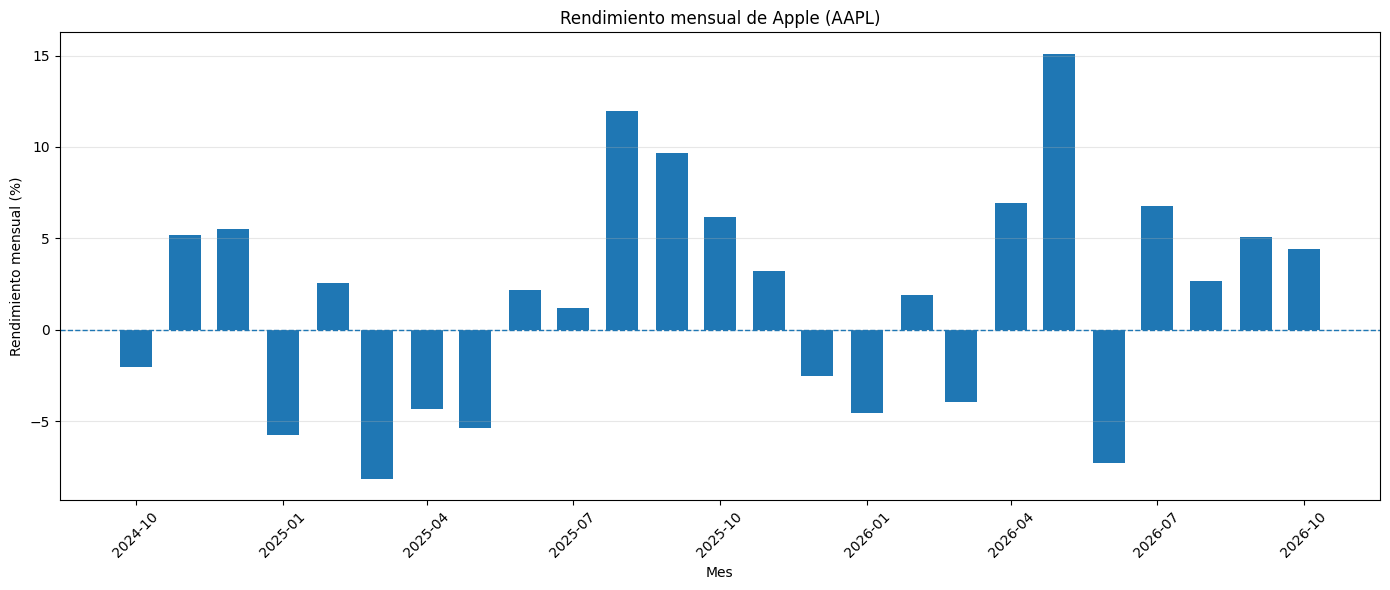

Rendimientos mensuales (%):
Date
2024-10-01    -2.02
2024-11-01     5.17
2024-12-01     5.52
2025-01-01    -5.76
2025-02-01     2.59
2025-03-01    -8.15
2025-04-01    -4.34
2025-05-01    -5.36
2025-06-01     2.15
2025-07-01     1.17
2025-08-01    11.96
2025-09-01     9.69
2025-10-01     6.18
2025-11-01     3.24
2025-12-01    -2.51
2026-01-01    -4.55
2026-02-01     1.91
2026-03-01    -3.93
2026-04-01     6.92
2026-05-01    15.11
2026-06-01    -7.27
2026-07-01     6.76
2026-08-01     2.66
2026-09-01     5.10
2026-10-01     4.42
Freq: MS, Name: AAPL, dtype: float64


In [11]:
# Completa aquí


import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

# Descargar datos de Apple
df = yf.download(
    "AAPL",
    period="2y",
    interval="1d",
    auto_adjust=True,
    progress=False
)

if df.empty:
    print("No se pudieron descargar los datos de AAPL.")
else:
    cierre = df["Close"]

    # Manejar posibles columnas de varios niveles
    if isinstance(cierre, pd.DataFrame):
        cierre = cierre.iloc[:, 0]

    # Calcular rendimientos diarios
    rendimientos = cierre.pct_change()

    # Calcular rendimiento mensual acumulado
    rendimiento_mensual = (
        (1 + rendimientos)
        .groupby(rendimientos.index.to_period("M"))
        .prod()
        .sub(1) * 100
    )

    # Convertir los periodos mensuales a fechas
    rendimiento_mensual.index = (
        rendimiento_mensual.index.to_timestamp()
    )

    # Graficar la comparación mensual
    plt.figure(figsize=(14, 6))
    plt.bar(
        rendimiento_mensual.index,
        rendimiento_mensual.values,
        width=20
    )
    plt.axhline(0, linestyle="--", linewidth=1)

    plt.title("Rendimiento mensual de Apple (AAPL)")
    plt.xlabel("Mes")
    plt.ylabel("Rendimiento mensual (%)")
    plt.xticks(rotation=45)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

    print("Rendimientos mensuales (%):")
    print(rendimiento_mensual.round(2))



## 9. Proyección corta
Plantee una proyección sencilla de corto plazo (por ejemplo, promedio móvil o regresión lineal) y explique sus limitaciones.

Último precio de cierre: 347.73
Promedio móvil de 20 días: 338.91

Proyección de referencia para los próximos 5 días:
2026-10-26    338.91
2026-10-27    338.91
2026-10-28    338.91
2026-10-29    338.91
2026-10-30    338.91
Freq: B, dtype: float64


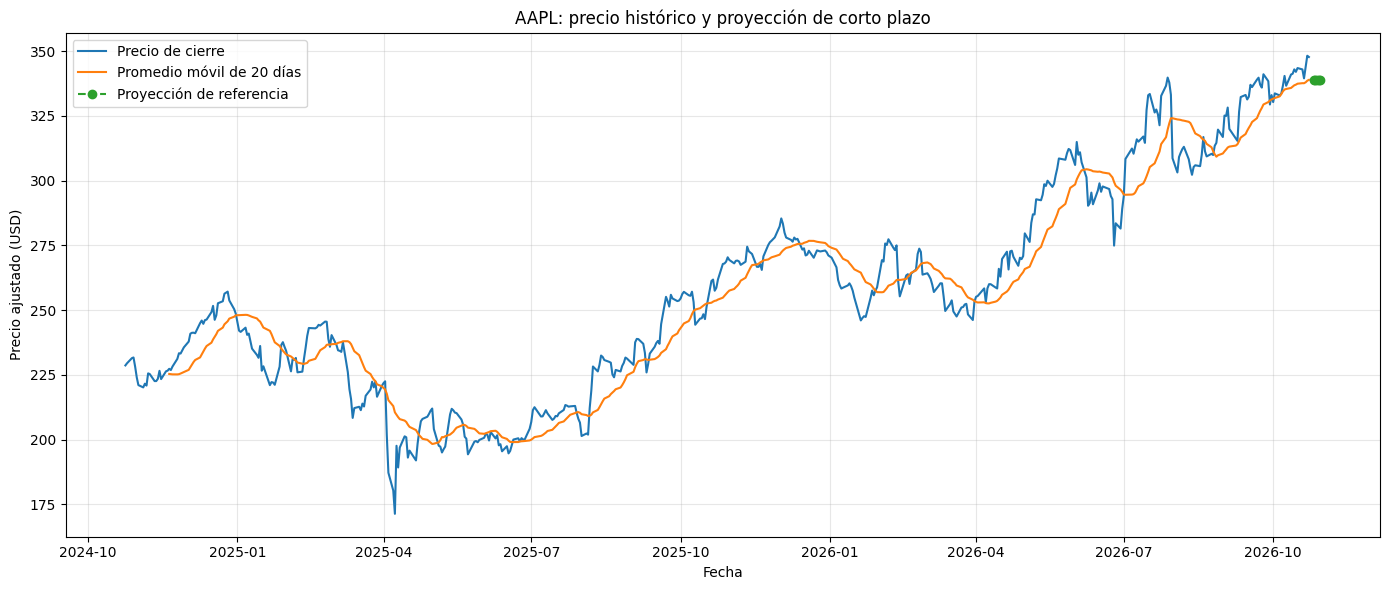

In [12]:
# Completa aquí


import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

# Descargar datos de Apple de los últimos dos años
df = yf.download(
    "AAPL",
    period="2y",
    interval="1d",
    auto_adjust=True,
    progress=False
)

if df.empty:
    print("No se pudieron descargar los datos de AAPL.")
else:
    cierre = df["Close"]

    # Manejar columnas de varios niveles
    if isinstance(cierre, pd.DataFrame):
        cierre = cierre.iloc[:, 0]

    cierre = cierre.dropna()

    # Calcular promedio móvil de 20 días
    promedio_movil = cierre.rolling(window=20).mean()

    # Proyección sencilla: mantener el último promedio móvil
    ultima_fecha = cierre.index[-1]
    ultima_media = promedio_movil.iloc[-1]

    # Próximos 5 días hábiles bursátiles aproximados
    fechas_futuras = pd.bdate_range(
        start=ultima_fecha + pd.Timedelta(days=1),
        periods=5
    )

    proyeccion = pd.Series(
        [ultima_media] * 5,
        index=fechas_futuras
    )

    # Mostrar el resultado de la proyección
    print("Último precio de cierre:", round(float(cierre.iloc[-1]), 2))
    print("Promedio móvil de 20 días:", round(float(ultima_media), 2))
    print("\nProyección de referencia para los próximos 5 días:")
    print(proyeccion.round(2))

    # Graficar
    plt.figure(figsize=(14, 6))
    plt.plot(cierre.index, cierre, label="Precio de cierre")
    plt.plot(
        promedio_movil.index,
        promedio_movil,
        label="Promedio móvil de 20 días"
    )
    plt.plot(
        proyeccion.index,
        proyeccion,
        linestyle="--",
        marker="o",
        label="Proyección de referencia"
    )

    plt.title("AAPL: precio histórico y proyección de corto plazo")
    plt.xlabel("Fecha")
    plt.ylabel("Precio ajustado (USD)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


El promedio móvil de 20 días representa el precio promedio de cierre de las últimas 20 sesiones bursátiles.

La proyección mantiene ese último promedio como referencia para los cinco días siguientes. Por tanto, no predice cambios diarios específicos, sino que establece un escenario sencillo basado en el comportamiento reciente.

 Limitaciones de la proyección No anticipa cambios inesperados: noticias económicas, resultados empresariales o decisiones de la Reserva Federal pueden modificar el precio. Reacciona con retraso: el promedio móvil utiliza precios pasados y puede tardar en reflejar un cambio de tendencia.

  No incorpora todas las variables: no considera directamente el volumen negociado, la volatilidad futura ni otros factores del mercado. No garantiza resultados: la proyección es una referencia estadística y no una predicción segura del precio futuro.
  
  En conclusión, el promedio móvil de 20 días es útil para identificar tendencias recientes y construir un escenario básico de corto plazo, pero debe complementarse con otras herramientas de análisis antes de tomar decisiones de inversión.

## 10. Conclusión financiera
Redacte tres conclusiones concretas sobre comportamiento, riesgo y límites del análisis.

1.AAPL presentó variaciones en su precio de cierre durante el período analizado. El estudio de los precios y los rendimientos diarios permite identificar períodos de crecimiento y disminución, así como observar la evolución de su comportamiento en el mercado.

2.Riesgo: La volatilidad móvil de 20 días permite identificar períodos de mayor y menor variabilidad en los rendimientos de AAPL. Una volatilidad elevada indica mayores fluctuaciones del precio y, por tanto, una mayor incertidumbre para los inversionistas.


3.Limitaciones del análisis: La proyección basada en el promedio móvil de 20 días ofrece una referencia sencilla del comportamiento reciente, pero no garantiza que los precios futuros sigan la misma tendencia. Además, el análisis utiliza datos históricos y no incorpora todos los factores económicos, financieros y empresariales que pueden afectar el precio de la acción. .

## 11. Video de sustentación
Pegue el enlace de su video individual (máximo 5 minutos). En el video explique su activo, sus gráficos y sus conclusiones.

*[Enlace]*